Advanced Derivatives Coursework

# I/ Black-Scholes-Merton Hedging

## a) Setup

In [2]:
### IMPORTS

from financepy.models.black_scholes_analytic import (
    european_value as bs_value,
    delta as bs_delta,
    gamma as bs_gamma,
)

from financepy.utils.global_types import OptionTypes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Default Values for our Parameter

S0 = 100
K = 100
T = 1
sigma = 0.20
r = 0.04
q = 0
mu = 0.08
N = 12

In [ ]:
### Testing the functions

v = bs_value(S0, T, K, r, q, sigma, OptionTypes.EUROPEAN_CALL.value)
delta = bs_delta(S0, T, K, r, q, sigma, OptionTypes.EUROPEAN_CALL.value)

b

## b) Delta Hedging of a European Put

In [16]:
def DeltaHedge(S=S0, T=T, K=K, r=r, mu=mu, q=q, sigma=sigma,
               OptionType=OptionTypes.EUROPEAN_PUT.value, N=N, *, M=None, rng=None):
    if T <= 0 or N <= 0:
        raise ValueError("T and N must be positive")

    # The same update works for a scalar spot or an array of independent paths.
    if M is not None:
        S = np.full(M, S, dtype=float)
    if rng is None:
        rng = np.random

    delta = bs_delta(S, T, K, r, q, sigma, OptionType)
    v = bs_value(S, T, K, r, q, sigma, OptionType)
    B = delta * S - v
    realized_variance = 0.0
    gamma_integral = 0.0

    t = 0.0
    for i in range(int(np.ceil(T * N))):
        next_t = min((i + 1) / N, T)
        dt = next_t - t
        if dt <= 0:
            break

        gamma_integral += bs_gamma(S, T - t, K, r, q, sigma, OptionType) * dt
        log_return = (mu - 0.5 * sigma ** 2) * dt + sigma * np.sqrt(dt) * rng.normal(size=M)
        realized_variance += log_return ** 2
        S = S * np.exp(log_return)

        next_delta = bs_delta(S, T - next_t, K, r, q, sigma, OptionType) if next_t < T else delta
        B = B * np.exp(r * dt) + (next_delta - delta) * S
        delta = next_delta
        t = next_t

    ST = S
    option_payoff = np.maximum(0, K - ST)
    replicating_error = delta * ST - B - option_payoff
    avg_gamma = gamma_integral / T
    return ST, option_payoff, realized_variance, replicating_error, avg_gamma

In [17]:
DeltaHedge()

(np.float64(100.8345902396142),
 np.float64(0.0),
 np.float64(0.029494512408040637),
 np.float64(2.068754500706163),
 np.float64(0.026265216754468867))

## c) Hedging Error over 10 000 different paths

In [18]:
def hedging_error(S=S0, T=T, K=K, r=r, mu=mu, q=q, sigma=sigma,
                  OptionType=OptionTypes.EUROPEAN_PUT.value, N=N, M=10_000,
                  *, seed=None, return_paths=False):
    ST, payoff, realized_var, error, average_gamma = DeltaHedge(
        S, T, K, r, mu, q, sigma, OptionType, N, M=M, rng=np.random.default_rng(seed)
    )
    if return_paths:
        return pd.DataFrame({
            "ST": ST,
            "option_payoff": payoff,
            "realized_variance": realized_var,
            "realized_volatility": np.sqrt(realized_var / T),
            "replicating_error": error,
            "average_gamma": average_gamma,
        })
    return error, ST

In [19]:
hedging_error(return_paths=True, seed=42).head()

,ST,option_payoff,realized_variance,realized_volatility,replicating_error,average_gamma
0,80.050190,19.949810,0.048762,0.220820,-0.928492,0.020090
1,113.125100,0.000000,0.056604,0.237916,-2.899764,0.024394
2,114.216712,0.000000,0.055085,0.234702,-3.592708,0.027847
3,91.015752,8.984248,0.046210,0.214966,-3.216816,0.028606
4,93.243376,6.756624,0.082574,0.287357,-4.220576,0.019295


d

## d) Hedging Error for various hedging frequencies 

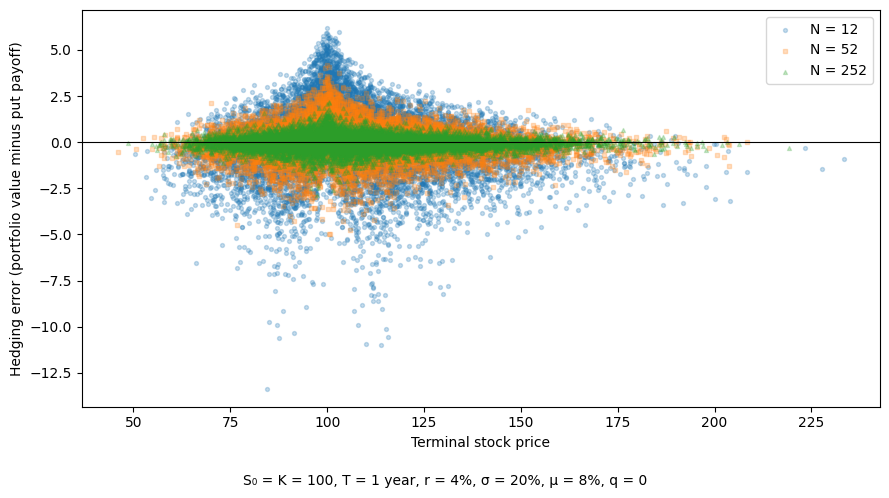

In [11]:
frequencies = (12, 52, 252)
paths_by_N = {
    frequency: hedging_error(
        S=100, T=1, K=100, r=0.04, mu=0.08, q=0, sigma=0.20,
        N=frequency, M=10_000, seed=2026 + frequency, return_paths=True,
    )
    for frequency in frequencies
}

fig, ax = plt.subplots(figsize=(9, 5))
for frequency, marker in zip(frequencies, ("o", "s", "^")):
    paths = paths_by_N[frequency]
    ax.scatter(paths["ST"], paths["replicating_error"], s=8, alpha=0.25,
               marker=marker, label=f"N = {frequency}")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Terminal stock price")
ax.set_ylabel("Hedging error (portfolio value minus put payoff)")
ax.legend()
fig.text(0.5, 0.02, "S₀ = K = 100, T = 1 year, r = 4%, σ = 20%, μ = 8%, q = 0",
         ha="center")
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## e) Mean and variance of the hedging error

In [20]:
### The table uses the 10,000 paths per frequency simulated in 1(d). Variances are sample variances.

errors_by_N = pd.DataFrame({
    frequency: paths["replicating_error"] for frequency, paths in paths_by_N.items()
})
hedging_summary = pd.DataFrame({
    "Mean hedging error": errors_by_N.mean(),
    "Variance of hedging error": errors_by_N.var(ddof=1),
}).rename_axis("N")
hedging_summary.round(6)

,Mean hedging error,Variance of hedging error
N,,
12,-0.037935,3.788556
52,0.009380,0.899831
252,-0.002303,0.185646


## f) Realized volatility and replication error

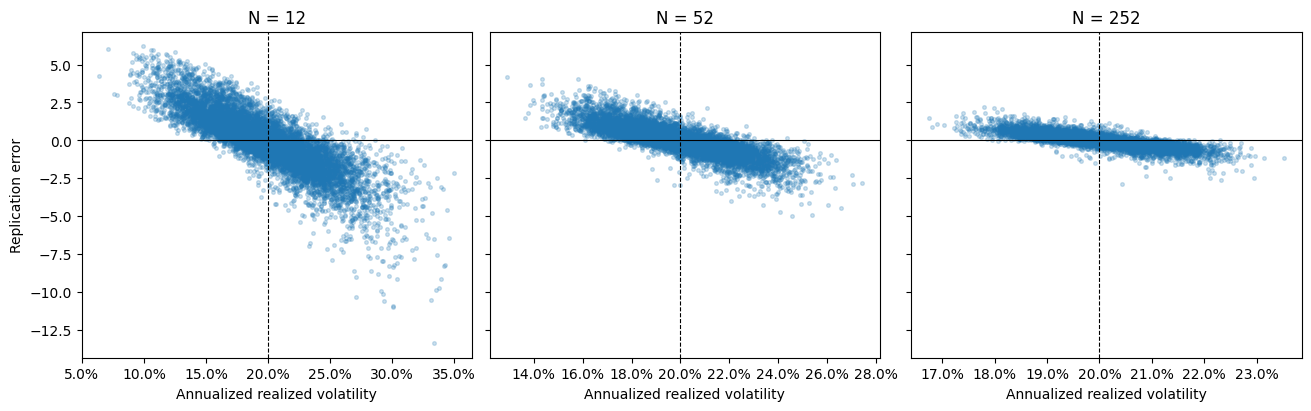

In [13]:
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
for ax, (frequency, paths) in zip(axes, paths_by_N.items()):
    ax.scatter(paths["realized_volatility"], paths["replicating_error"], s=7, alpha=0.22)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0.20, color="black", linestyle="--", linewidth=0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_title(f"N = {frequency}")
    ax.set_xlabel("Annualized realized volatility")
axes[0].set_ylabel("Replication error")
plt.show()

The clouds slope downward. A put has positive gamma, so large stock moves tend to increase the option value beyond what the frozen delta position earns over that interval. For the short put, this tends to reduce the replication error when realized volatility is high. The relevant local weight is proportional to $S^2\Gamma$, which changes along the path. Two paths with similar realized volatility can therefore have different errors. The dashed line marks the 20% volatility used for pricing and hedging.

## g) Average gamma and replication error

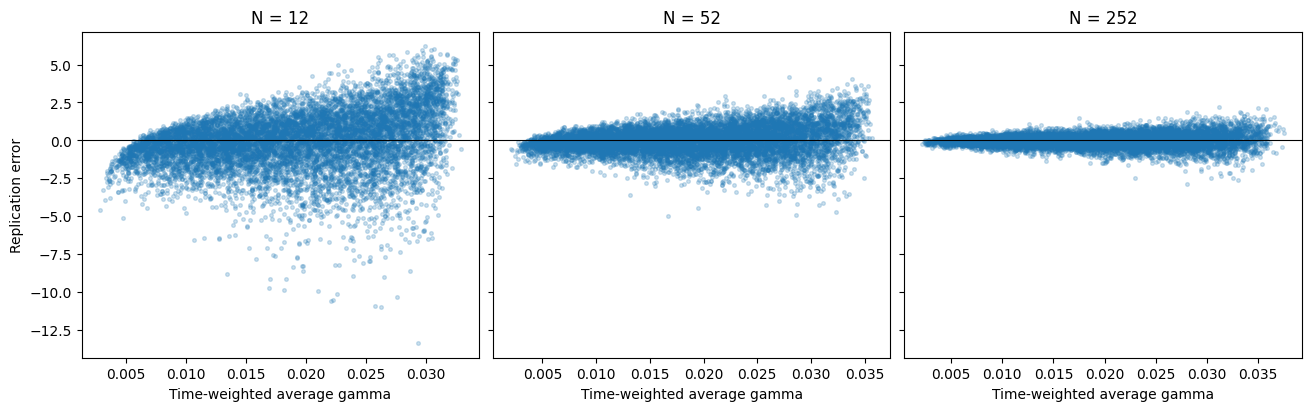

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
for ax, (frequency, paths) in zip(axes, paths_by_N.items()):
    ax.scatter(paths["average_gamma"], paths["replicating_error"], s=7, alpha=0.22)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"N = {frequency}")
    ax.set_xlabel("Time-weighted average gamma")
axes[0].set_ylabel("Replication error")
plt.show()

The spread of the errors generally increases at higher average gamma. These paths tend to spend more time near the strike, where the put's delta is more sensitive to changes in the stock price. A fixed delta can therefore produce larger gains or losses between rebalances. The sign depends on the realized moves relative to the model variance on the intervals where gamma is high. More frequent rebalancing narrows the spread.

### 1(h) Sensitivity to the stock drift

The four scenarios use the same 10,000 independent sets of normal draws. Reusing the draws across scenarios makes it easier to compare the effect of changing drift. The option price and hedge ratios are computed with the same risk-free rate and model volatility in every scenario.

In [15]:
drifts = (0.025, 0.050, 0.075, 0.100)
drift_errors = pd.DataFrame({
    f"{drift:.1%}": hedging_error(
        S=100, T=1, K=100, r=0.04, mu=drift, q=0, sigma=0.20,
        N=52, M=10_000, seed=2052, return_paths=True,
    )["replicating_error"]
    for drift in drifts
})
drift_summary = pd.DataFrame({
    "Mean absolute hedging error": drift_errors.abs().mean(),
    "Variance of hedging error": drift_errors.var(ddof=1),
}).rename_axis("Drift (μ)")
drift_summary.round(6)

,Mean absolute hedging error,Variance of hedging error
Drift (μ),,
2.5%,0.716688,0.908442
5.0%,0.712507,0.898367
7.5%,0.703407,0.875021
10.0%,0.693677,0.858646


The mean absolute error ranges from 0.6937 to 0.7167, and the error variance ranges from 0.8586 to 0.9084. The effect of changing the drift is small for this put and weekly hedge. Drift shifts where the stock tends to trade and therefore changes its exposure to gamma along the path. Over a short rebalance interval, the drift contribution scales with the interval length, while the volatility contribution scales with its square root. Changing the rebalance frequency has a much larger effect on error variance in 1(e).

# II/ Valuation of Options under time-varying volatility

## a)

In [56]:
def put_pricing_under_2_vol_regimes(S0=100, K=100, r=0.04, mu=0.08, q=0, sigma_1=0.04, sigma_2 = 0.28, T1 = 0.5, T2 = 0.5, OptionType=OptionTypes.EUROPEAN_PUT.value, N=252) :
    price_path = [S0]
    for i in range(N) :
        if i < T1/(T1+T2) :
            sigma = sigma_1
        else :
            sigma = sigma_2
        price_path.append(price_path[i]*np.exp( (mu - (sigma**2)/2)*T/N  +  sigma*np.sqrt(T/N)*np.random.normal()))
    payoff = np.max([price_path[-1] - K, 0])
    return payoff


In [60]:
nb_traj = 1000
payoffs = []
for i in range(nb_traj) :
    payoffs.append(put_pricing_under_2_vol_regimes())
np.mean(payoffs)

np.float64(15.918355085199144)